In [156]:
# Bibliotecas utilizadas

import numpy as np
import matplotlib.pyplot as plt

# Constantes 

pi = np.pi

# DFT de um sinal de tempo discreto #

Seja $x(n)$ um sinal de tempo discreto de comprimento $L$, isto é, definido para $n=0,1,...,L-1$, sua DFT de $N\geq L$ pontos é dada por:

$$X(k)= \sum\limits_{n=0}^{N-1}x(n)e^{-j\frac{2\pi k}{N}n}\,,\,k=0,1,...,N-1\,.$$

A equação de sintese é:

$$
x(n) = 
\begin{cases}
    \frac{1}{N}\sum\limits_{k=0}^{N-1}X(k)e^{j\frac{2\pi k}{N}n}\,,\,n=0,1,...,N-1 \\
    0\hspace{2.45cm},\,\text{caso contrário}
\end{cases}
\,.
$$

## Funções ##

In [157]:
def DFT(x, k, N):
    x_copy = x.copy()

    if N < L:
        raise Exception("N deve ser maior ou igual a L")
    if (k < 0) or (k > N-1) or (int(k) != k):
        raise Exception("k deve ser um inteiro entre 0 e N-1")
    if N > L:
        x_copy = np.append(x_copy, [0]*(N-L))

    X = 0
    for n in range(0, N):
        exp = np.exp(-2j*pi*k*n/N)
        xn = x_copy[n]
        X += xn*exp
    return X

def IDFT(X, n):
    if int(n) != n:
        raise Exception("n deve ser um inteiro")
    
    N = len(X)

    if (n < 0) or (n > N-1):
        return 0

    sum = 0
    for k in range(0,N):
        exp = np.exp(2j*pi*k*n/N)
        sum += X[k]*exp
    x = sum/N
    return x

## Aplicações ##

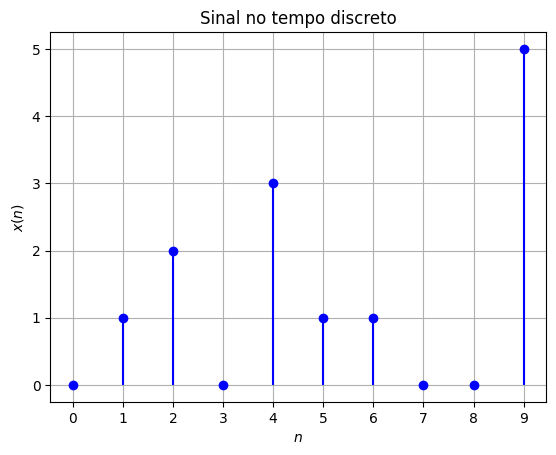

In [158]:
L = 10
A = 1

n_array = np.arange(0, L, 1)
#x = A*np.ones(L)
x = [0,1,2,0,3,1,1,0,0,5]

plt.stem(n_array, x, basefmt=" ", linefmt='b-')
plt.grid(True)
plt.title('Sinal no tempo discreto')
plt.xlabel(r'$n$')
plt.xticks(n_array)
plt.ylabel(r'$x(n)$')
plt.show()

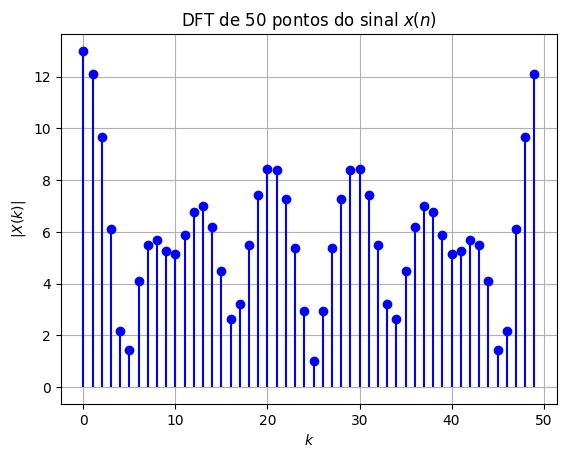

In [159]:
N = 50
k_array = np.arange(0, N, 1)

X = []
for k in k_array:
    X.append(DFT(x, k, N))
X = np.array(X)


plt.stem(k_array, np.abs(X), basefmt=" ", linefmt='b-')
plt.grid(True)
plt.title(r'DFT de %d pontos do sinal $x(n)$' %N)
plt.xlabel(r'$k$')
if N < 21:
    plt.xticks(k_array)
plt.ylabel(r'$|X(k)|$')
plt.show()

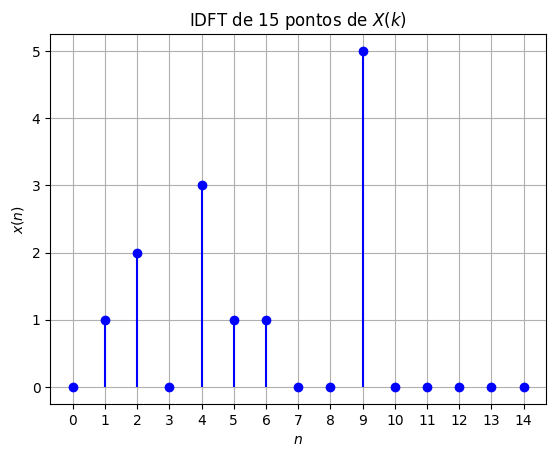

In [161]:
N = 15
n_array = np.arange(0, N, 1)

x_IDFT = []
for n in n_array:
    x_IDFT.append(IDFT(X, n))
x_IDFT = np.array(x_IDFT)

plt.stem(n_array, np.real(x_IDFT), basefmt=" ", linefmt='b-')
plt.grid(True)
plt.title(r'IDFT de $%d$ pontos de $X(k)$' %N)
plt.xlabel(r'$n$')
if N < 21:
    plt.xticks(n_array)
plt.ylabel(r'$x(n)$')
plt.show()